<a href="https://colab.research.google.com/github/Krishna-Tyagi-sketch/customer-Churn-prediction/blob/main/Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# DATASET LINK : https://drive.google.com/file/d/1Qlj4AoKqbMq3CuGcxA0veMbpKLk42cpv/view?usp=sharing

### Problem Statement

Customer churn is a significant challenge for telecommunications companies, as retaining existing customers is often more cost-effective than acquiring new ones. The objective of this project is to develop a machine learning classification model that can identify customers who are likely to churn based on their demographic, service, contract, and billing-related information.

The dataset will be explored and preprocessed by identifying missing values, examining data distributions, handling relevant data inconsistencies, removing non-predictive identifiers, and converting categorical variables into a suitable numerical format. A **Random Forest Classifier** will then be trained to predict the customer churn status.

The performance of the model will be evaluated using appropriate classification metrics, including **accuracy and the classification report**. Furthermore, **GridSearchCV** will be used to perform hyperparameter tuning and identify a suitable combination of Random Forest parameters for improving model performance.

The overall objective is to develop a reliable churn prediction model that demonstrates how machine learning can be applied to identify customers who may be at risk of leaving a telecommunications service.



### Description of Dataset Columns

| Column Name | Description |
|---|---|
| customerID | Unique identifier assigned to each customer. |
| gender | Gender of the customer. |
| SeniorCitizen | Indicates whether the customer is a senior citizen. |
| Partner | Indicates whether the customer has a partner. |
| Dependents | Indicates whether the customer has dependents. |
| tenure | Number of months the customer has been associated with the telecom service. |
| PhoneService | Indicates whether the customer has phone service. |
| MultipleLines | Indicates whether the customer has multiple phone lines. |
| InternetService | Type of internet service used by the customer. |
| OnlineSecurity | Indicates whether the customer has an online security service. |
| OnlineBackup | Indicates whether the customer has an online backup service. |
| DeviceProtection | Indicates whether the customer has device protection service. |
| TechSupport | Indicates whether the customer has technical support service. |
| StreamingTV | Indicates whether the customer has a TV streaming service. |
| StreamingMovies | Indicates whether the customer has a movie streaming service. |
| Contract | Type of contract associated with the customer. |
| PaperlessBilling | Indicates whether the customer uses paperless billing. |
| PaymentMethod | Payment method used by the customer. |
| MonthlyCharges | Amount charged to the customer on a monthly basis. |
| TotalCharges | Total amount charged to the customer over the period of their service. |
| Churn | Indicates whether the customer has left the telecom service. This is the target variable. |


In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv('/content/customer_churn (1) (1) (3).csv')

In [ ]:
# EDA
df.shape

(7043, 21)

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# convert the dtype of TC into numeric
df['TotalCharges'].value_counts()

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8
...,...
130.15,1
3211.9,1
7843.55,1


In [ ]:
df['TotalCharges']=df['TotalCharges'].astype(float)

ValueError: could not convert string to float: ' '

In [ ]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df['TotalCharges']=df['TotalCharges'].fillna(df['MonthlyCharges']*df['tenure'])

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

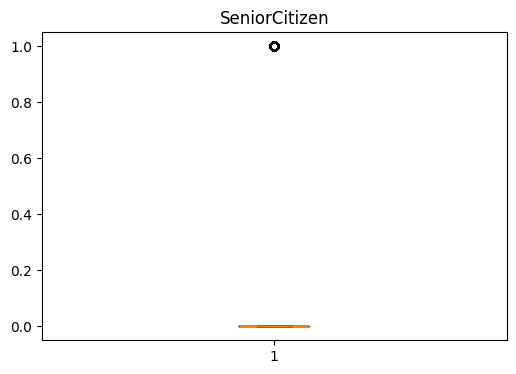

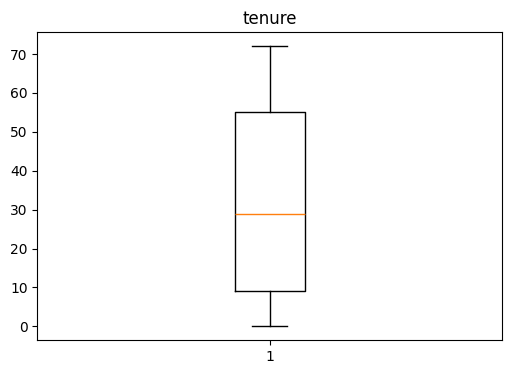

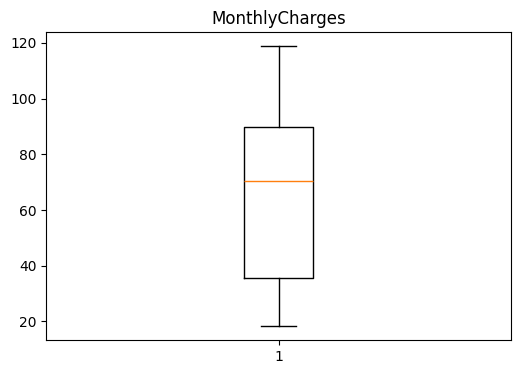

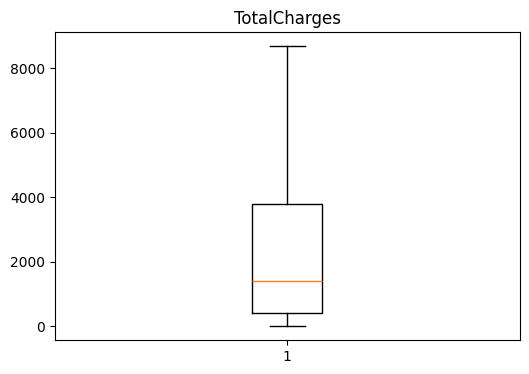

In [ ]:
for col in df.columns:
  if df[col].dtype!='object':
    plt.figure(figsize=(6,4))
    plt.boxplot(df[col])
    plt.title(col)
    plt.show()

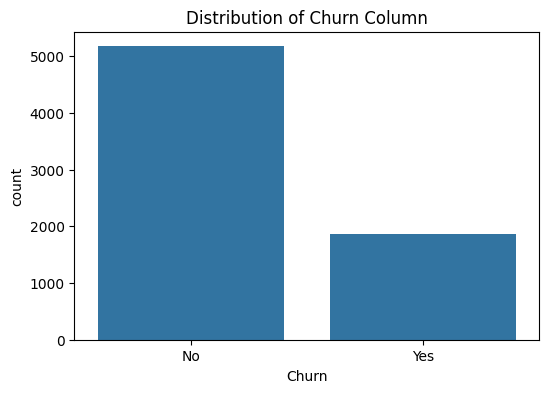

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Churn',data=df)
plt.title('Distribution of Churn Column')
plt.show()

In [ ]:
df.drop('customerID',axis=1,inplace=True)

In [ ]:
# Label encoding
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

for i in df.columns:
  if df[i].dtype == 'object':
    df[i]=le.fit_transform(df[i])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   int64  
 7   InternetService   7043 non-null   int64  
 8   OnlineSecurity    7043 non-null   int64  
 9   OnlineBackup      7043 non-null   int64  
 10  DeviceProtection  7043 non-null   int64  
 11  TechSupport       7043 non-null   int64  
 12  StreamingTV       7043 non-null   int64  
 13  StreamingMovies   7043 non-null   int64  
 14  Contract          7043 non-null   int64  
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   int64  


In [ ]:
# Model Building
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import *

# 1- split into x and y
# 2 - split into training and testing
# 3- train the model
# 4 - test the model

x=df.drop(columns=['Churn'])
y=df['Churn']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
model=RandomForestClassifier(random_state=42)

In [ ]:
model.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred=model.predict(x_test)
print(y_pred)

[1 0 0 ... 0 0 1]


In [ ]:
accuracy=accuracy_score(y_test,y_pred)
print('Accuracy:',accuracy)

Accuracy: 0.794889992902768


In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.47      0.55       373

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



### Hyperparameter Tuning

GridSearchCV is used to evaluate different combinations of the below hyperparameters using 2-fold cross-validation. The combination that provides the best accuracy is selected as the best parameter configuration for the Random Forest model.

### Hyperparameters Used for Random Forest

| Hyperparameter | Values Used | Description |
|---|---|---|
| n_estimators | 100, 200, 300 | Number of decision trees used in the Random Forest. |
| max_depth | None, 5, 10 | Maximum depth allowed for each decision tree. `None` means that the tree can grow until other stopping conditions are met. |
| min_samples_split | 2, 5, 10 | Minimum number of samples required to split an internal node. |
| min_samples_leaf | 1, 2, 3 | Minimum number of samples that must be present in a leaf node. |
| criterion | gini, entropy | Function used to measure the quality of a split. |

In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid={
    'n_estimators':[100,200,300],
    'max_depth':[None,5,10],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,3],
    'criterion':['gini','entropy']
}

model=RandomForestClassifier(random_state=42)
grid_search=GridSearchCV(estimator=model,param_grid=param_grid,cv=2,scoring='accuracy')
grid_search.fit(x_train,y_train)

GridSearchCV(cv=2, estimator=RandomForestClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 5, 10],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
print(grid_search.best_params_)

{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 300}
